<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)

# 01 · Reshaping JSON can discard information

**Can we normalize ticket labels without losing values or hiding missing data?**
We will guard malformed JSON, move nested fields with Jolt, supply an explicit review
state, and compare two cardinality policies. SQL will audit the original and transformed
values before any label chart is drawn.

All ten payload rows are **synthetic**. They include a scalar string, multi-value lists,
an empty list, explicit JSON null, a missing field, duplicate strings, a number, a mixed
string/null list, malformed JSON and a SQL NULL payload. Structural normalization does
not establish that a value is a meaningful business label.

## Choose the cardinality policy

`LABEL_CARDINALITY="MANY"` returns lists: it wraps a scalar and retains list elements.
The experiment uses `"ONE"`, which takes the first element of a list. These policies
are not interchangeable. Restart and run all after changing this string.
We retain original field-state diagnostics under either policy. [Run instructions](README.md).

In [1]:
LABEL_CARDINALITY = "MANY"

In [2]:
import os

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
import haybarn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display
from notebook_support import finish, prose, theme

if LABEL_CARDINALITY not in {"MANY", "ONE"}:
    raise ValueError('LABEL_CARDINALITY must be "MANY" or "ONE".')
comparison = labels = checks = pd.DataFrame()
theme()
con = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-jolt/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-jolt/notebooks/pyproject.toml.

## Connect to the pinned JAR release

The visible launcher downloads the public v0.4.0 JAR, checks its pinned SHA-256,
and starts Java 21+. Downloads and cache publication are locked; cached bytes are
verified before reuse. No Gradle or local worker build is needed. Haybarn's JSON
extension supplies the inspection and aggregation functions alongside the real Jolt worker.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
LOAD json;
ATTACH 'jolt' (TYPE vgi,
 LOCATION 'uv run --frozen --project . python release_jar.py Query-farm/vgi-jolt v0.4.0 vgi-jolt-v0.4.0.jar 6062855f47a80bf6207773afac5d99aca624da14d838332c31ba99803a101b31');
CREATE MACRO label_pipeline() AS '[
 {"operation":"shift","spec":{"ticket":{"id":"id","labels":"labels"}}},
 {"operation":"default","spec":{"review_state":"unreviewed"}},
 {"operation":"cardinality","spec":{"labels":"{{ LABEL_CARDINALITY }}"}}
]';
SELECT jolt.main.is_valid_jolt_spec(label_pipeline()) AS valid_pipeline;

,valid_pipeline
0,True


## Validate syntax and retain the input evidence

`json_valid` is the worker's nonthrowing guard. A malformed document is different
from a SQL NULL payload, and valid JSON can still have the wrong field type. The safe
copy is only populated for valid documents, so JSON inspection never parses a malformed
row. We keep the original payload and its input row identifier throughout.

In [4]:
%%sql
CREATE TABLE inputs(record_id INTEGER,payload VARCHAR);
INSERT INTO inputs VALUES
 (1,'{"ticket":{"id":"T1","labels":["billing","urgent","email"]}}'),
 (2,'{"ticket":{"id":"T2","labels":"account"}}'),
 (3,'{"ticket":{"id":"T3","labels":[]}}'),
 (4,'{"ticket":{"id":"T4","labels":null}}'),
 (5,'{"ticket":{"id":"T5"}}'),
 (6,'{"ticket":{"id":"T6","labels":["bug","bug","triage"]}}'),
 (7,'{"ticket":'),
 (8,NULL),
 (9,'{"ticket":{"id":"T9","labels":42}}'),
 (10,'{"ticket":{"id":"T10","labels":["bug",null]}}');
CREATE TABLE syntax_check AS SELECT *,jolt.main.json_valid(payload) AS valid_json FROM inputs;
CREATE TABLE safe_inputs AS
 SELECT *,CASE WHEN valid_json THEN payload END AS safe_payload FROM syntax_check;
CREATE TABLE classified AS
 SELECT *,
 CASE WHEN payload IS NULL THEN 'SQL NULL payload'
      WHEN NOT valid_json THEN 'malformed JSON'
      WHEN json_type(safe_payload,'$.ticket.labels') IS NULL THEN 'missing field'
      WHEN json_type(safe_payload,'$.ticket.labels')='NULL' THEN 'JSON null'
      WHEN json_type(safe_payload,'$.ticket.labels')='ARRAY' THEN 'array'
      WHEN json_type(safe_payload,'$.ticket.labels')='VARCHAR' THEN 'string'
      ELSE 'other JSON type' END AS original_label_state
 FROM safe_inputs;
SELECT record_id,valid_json,original_label_state,payload FROM classified ORDER BY record_id;

,record_id,valid_json,original_label_state,payload
0,1,True,array,"{""ticket"":{""id"":""T1"",""labels"":[""billing"",""urge..."
1,2,True,string,"{""ticket"":{""id"":""T2"",""labels"":""account""}}"
2,3,True,array,"{""ticket"":{""id"":""T3"",""labels"":[]}}"
3,4,True,JSON null,"{""ticket"":{""id"":""T4"",""labels"":null}}"
4,5,True,missing field,"{""ticket"":{""id"":""T5""}}"
5,6,True,array,"{""ticket"":{""id"":""T6"",""labels"":[""bug"",""bug"",""tr..."
6,7,False,malformed JSON,"{""ticket"":"
7,8,<NA>,SQL NULL payload,None
8,9,True,other JSON type,"{""ticket"":{""id"":""T9"",""labels"":42}}"
9,10,True,array,"{""ticket"":{""id"":""T10"",""labels"":[""bug"",null]}}"


## Apply the chain, then inspect what changed

`shift` copies only the specified paths; unmapped fields are not an automatic passthrough.
`default` assigns our declared workflow value `review_state="unreviewed"`. It is an
explicit synthetic policy, not a fact discovered in the source. `cardinality` then
normalizes labels according to the visible parameter.

Jolt treats explicit null and empty lists differently under these operations:
MANY turns explicit null into `[]`; ONE turns an empty list into null. Missing fields
remain absent. Original diagnostics prevent those output states from rewriting history.

In [5]:
%%sql
CREATE TABLE transformed AS
 SELECT *,CASE WHEN valid_json THEN jolt.main.jolt_transform(payload,label_pipeline()) END AS normalized_json
 FROM classified;
SELECT record_id,original_label_state,
       json_type(normalized_json,'$.labels') AS output_label_type,
       json_extract(normalized_json,'$.labels') AS output_labels,
       normalized_json
FROM transformed ORDER BY record_id;

,record_id,original_label_state,output_label_type,output_labels,normalized_json
0,1,array,ARRAY,"[""billing"",""urgent"",""email""]","{""id"":""T1"",""labels"":[""billing"",""urgent"",""email..."
1,2,string,ARRAY,"[""account""]","{""id"":""T2"",""review_state"":""unreviewed"",""labels..."
2,3,array,ARRAY,[],"{""id"":""T3"",""labels"":[],""review_state"":""unrevie..."
3,4,JSON null,ARRAY,[],"{""id"":""T4"",""labels"":[],""review_state"":""unrevie..."
4,5,missing field,None,None,"{""id"":""T5"",""review_state"":""unreviewed""}"
5,6,array,ARRAY,"[""bug"",""bug"",""triage""]","{""id"":""T6"",""labels"":[""bug"",""bug"",""triage""],""re..."
6,7,malformed JSON,None,None,None
7,8,SQL NULL payload,None,None,None
8,9,other JSON type,ARRAY,[42],"{""id"":""T9"",""review_state"":""unreviewed"",""labels..."
9,10,array,ARRAY,"[""bug"",null]","{""id"":""T10"",""labels"":[""bug"",null],""review_stat..."


## Audit individual values and their multiplicity

Expand the original and normalized label fields independently. Only JSON string values
are counted as known labels; numbers and null elements remain visible as other values.
This is a type rule, not a label taxonomy or text-content validation rule.

For comparable string/array inputs, the counts preserve duplicates. Missing, null,
malformed and wrong-type fields get NULL comparison counts, not invented zero labels.
The genuine empty array remains a known zero. Jolt output key order is unspecified,
so all comparisons use extracted values rather than serialized JSON text equality.

In [6]:
%%sql
CREATE TABLE original_values AS
 SELECT t.record_id,j.key AS position,j.type AS value_type,
        json_extract_string(j.value,'$') AS label
 FROM transformed t,LATERAL json_each(json_extract(t.safe_payload,'$.ticket.labels')) j;
CREATE TABLE output_values AS
 SELECT t.record_id,j.key AS position,j.type AS value_type,
        json_extract_string(j.value,'$') AS label
 FROM transformed t,LATERAL json_each(json_extract(t.normalized_json,'$.labels')) j;
CREATE TABLE value_counts AS
WITH before_counts AS (
 SELECT record_id,count(*) FILTER(WHERE value_type='VARCHAR') AS strings,
        count(*) FILTER(WHERE value_type!='VARCHAR') AS other_values
 FROM original_values GROUP BY record_id
), after_counts AS (
 SELECT record_id,count(*) FILTER(WHERE value_type='VARCHAR') AS strings,
        count(*) FILTER(WHERE value_type!='VARCHAR') AS other_values
 FROM output_values GROUP BY record_id
)
SELECT t.record_id,t.original_label_state,
 CASE WHEN t.original_label_state IN ('array','string') THEN coalesce(b.strings,0) END AS original_strings,
 CASE WHEN t.original_label_state IN ('array','string') THEN coalesce(a.strings,0) END AS retained_strings,
 CASE WHEN t.valid_json THEN coalesce(b.other_values,0) END AS original_other_values,
 CASE WHEN t.valid_json THEN coalesce(a.other_values,0) END AS output_other_values
FROM transformed t LEFT JOIN before_counts b USING(record_id) LEFT JOIN after_counts a USING(record_id);
SELECT *,original_strings-retained_strings AS lost_string_occurrences FROM value_counts ORDER BY record_id;

,record_id,original_label_state,original_strings,retained_strings,original_other_values,output_other_values,lost_string_occurrences
0,1,array,3,3,0,0,0
1,2,string,1,1,0,0,0
2,3,array,0,0,0,0,0
3,4,JSON null,<NA>,<NA>,1,0,<NA>
4,5,missing field,<NA>,<NA>,0,0,<NA>
5,6,array,3,3,0,0,0
6,7,malformed JSON,<NA>,<NA>,<NA>,<NA>,<NA>
7,8,SQL NULL payload,<NA>,<NA>,<NA>,<NA>,<NA>
8,9,other JSON type,<NA>,<NA>,1,1,<NA>
9,10,array,1,1,1,1,0


In [7]:
%%sql comparison <<
SELECT *,original_strings-retained_strings AS lost_string_occurrences
FROM value_counts WHERE original_strings IS NOT NULL ORDER BY record_id;

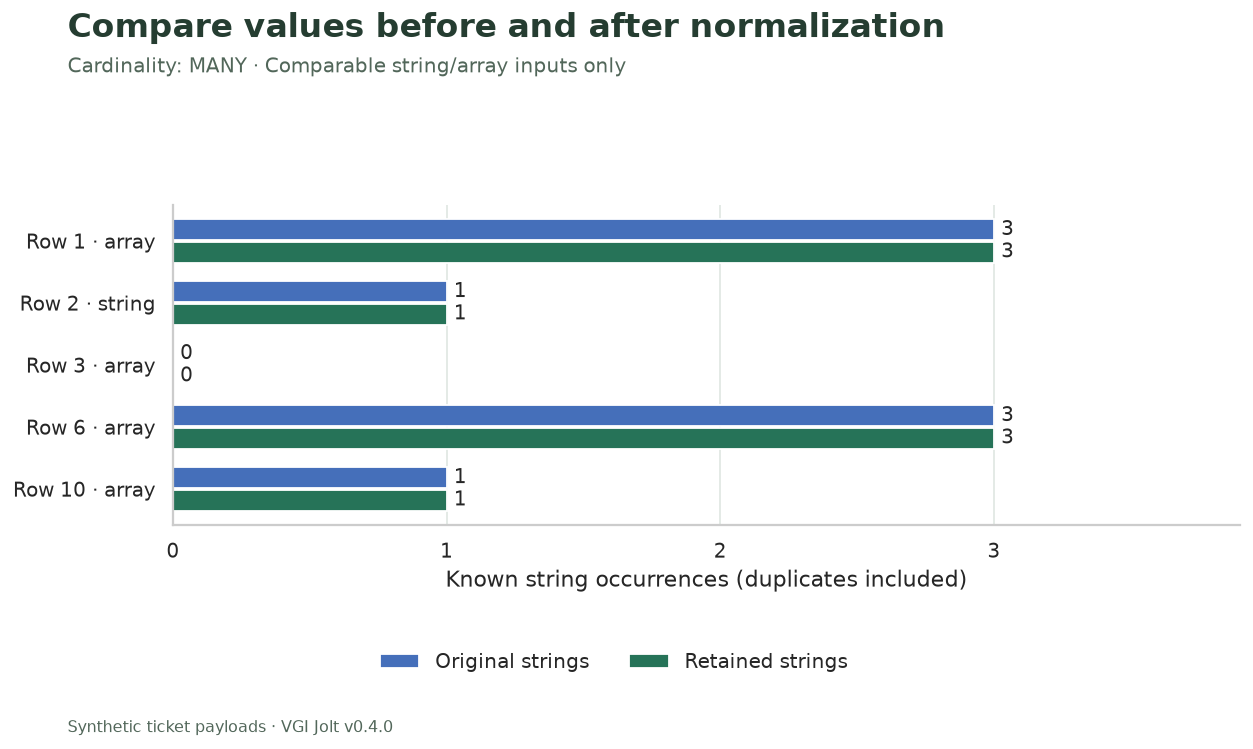

Across **5 comparable rows**, **8 of 8 known string occurrences** remain under **MANY**. The policy drops **0 occurrences**. The diagnostic table still retains every source row, including unavailable or wrong-type label fields.

In [8]:
fig, ax = plt.subplots(figsize=(10, 5.8))
y = np.arange(len(comparison))
for offset, column, color, label in [
    (-0.18, "original_strings", "#456fba", "Original strings"),
    (0.18, "retained_strings", "#267358", "Retained strings"),
]:
    bars = ax.barh(y + offset, comparison[column], height=0.34, color=color, label=label)
    ax.bar_label(bars, padding=4, fontsize=11)
ax.set_yticks(y, [f"Row {r.record_id} · {r.original_label_state}" for r in comparison.itertuples()])
ax.invert_yaxis()
ax.set_xlabel("Known string occurrences (duplicates included)")
ax.set_xlim(0, max(comparison.original_strings.max(), 1) * 1.3)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", visible=False)
fig.legend(
    *ax.get_legend_handles_labels(),
    loc="lower center",
    bbox_to_anchor=(0.5, 0.08),
    ncol=2,
    frameon=False,
)
finish(
    fig,
    "Compare values before and after normalization",
    f"Cardinality: {LABEL_CARDINALITY} · Comparable string/array inputs only",
    "01_string_retention.png",
    bottom=0.18,
)
original_count = int(comparison.original_strings.sum())
retained_count = int(comparison.retained_strings.sum())
prose(
    f"Across **{len(comparison)} comparable rows**, **{retained_count} of {original_count} known string occurrences** "
    f"remain under **{LABEL_CARDINALITY}**. The policy drops **{original_count - retained_count} occurrences**. "
    "The diagnostic table still retains every source row, including unavailable or wrong-type label fields."
)

## Count occurrences and tickets separately

A repeated label can occur twice in the same ticket. The first measure below counts
retained string occurrences; the second counts distinct synthetic ticket rows with that
label. Neither should be confused with a count of transformed JSON documents. Input
row IDs are unique here, and the checks also verify the source ticket IDs are unique.

In [9]:
%%sql labels <<
SELECT label,count(*) AS occurrences,count(DISTINCT record_id) AS tickets
FROM output_values WHERE value_type='VARCHAR'
GROUP BY label ORDER BY occurrences DESC,label;

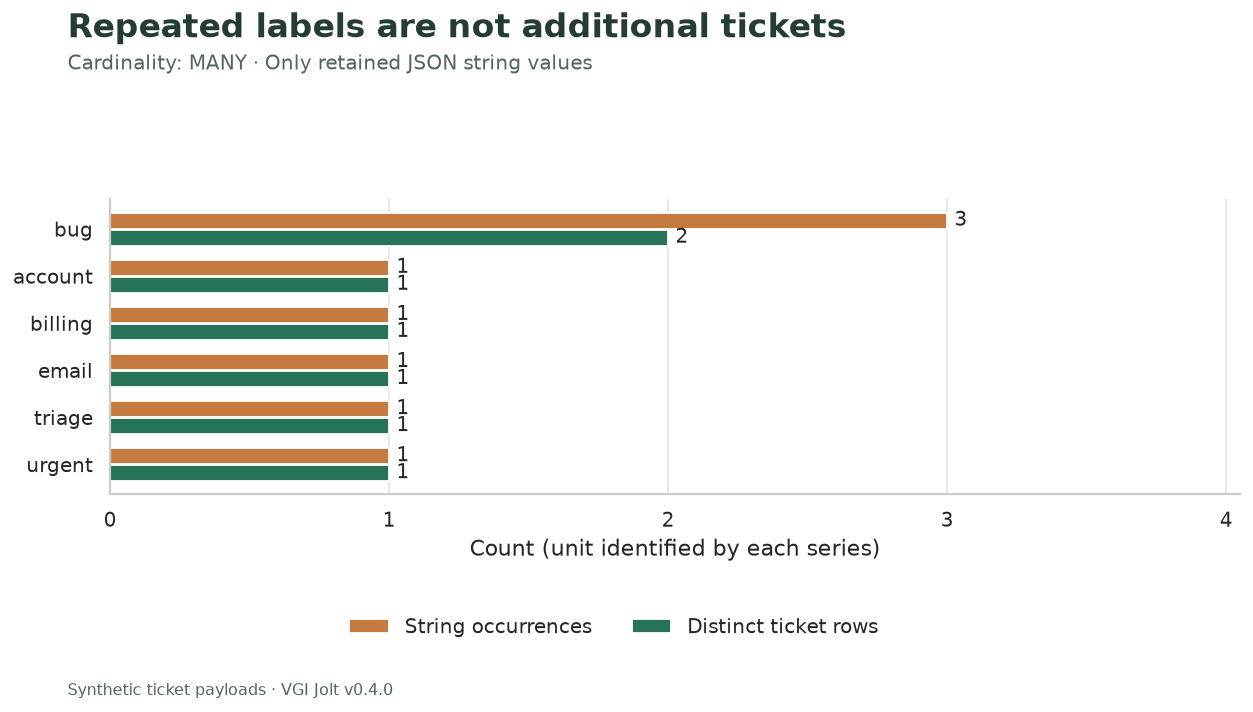

The normalized output has **8 known string occurrences** across **7 distinct ticket–label pairs**. That pair count is not a count of all tickets: one ticket can contribute to several labels, while a ticket with no known string labels contributes to none.

In [10]:
fig, ax = plt.subplots(figsize=(10, max(5.5, 2.7 + 0.4 * len(labels))))
y = np.arange(len(labels))
for offset, column, color, label in [
    (-0.18, "occurrences", "#c57b40", "String occurrences"),
    (0.18, "tickets", "#267358", "Distinct ticket rows"),
]:
    bars = ax.barh(y + offset, labels[column], height=0.34, color=color, label=label)
    ax.bar_label(bars, padding=4, fontsize=11)
ax.set_yticks(y, labels.label)
ax.invert_yaxis()
ax.set_xlabel("Count (unit identified by each series)")
ax.set_xlim(0, max(labels.occurrences.max(), 1) * 1.35)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.grid(axis="y", visible=False)
fig.legend(
    *ax.get_legend_handles_labels(),
    loc="lower center",
    bbox_to_anchor=(0.5, 0.08),
    ncol=2,
    frameon=False,
)
finish(
    fig,
    "Repeated labels are not additional tickets",
    f"Cardinality: {LABEL_CARDINALITY} · Only retained JSON string values",
    "02_occurrences_and_tickets.png",
    bottom=0.18,
)
prose(
    f"The normalized output has **{int(labels.occurrences.sum())} known string occurrences** across "
    f"**{int(labels.tickets.sum())} distinct ticket–label pairs**. That pair count is not a count of all tickets: "
    "one ticket can contribute to several labels, while a ticket with no known string labels contributes to none."
)

## Check preservation without claiming semantic equivalence

These checks reconcile row identity, guards, types and string multiplicities. They do
not claim that null and empty mean the same thing, or that choosing ONE is lossless.
The loss count and original-state diagnostics are part of the result, not exceptions
to be hidden when the experiment runs.

In [11]:
%%sql checks <<
SELECT 'Pipeline compiles as a Jolt chain' AS invariant,
       jolt.main.is_valid_jolt_spec(label_pipeline()) AS passed
UNION ALL SELECT 'Every input row survives with its unique row ID',
 (SELECT count(*)=count(DISTINCT record_id) AND count(*)=(SELECT count(*) FROM inputs) FROM transformed)
UNION ALL SELECT 'Invalid and SQL NULL payloads are not transformed',
 NOT EXISTS(SELECT 1 FROM transformed WHERE NOT coalesce(valid_json,false) AND normalized_json IS NOT NULL)
UNION ALL SELECT 'Valid source ticket IDs survive the shift',
 NOT EXISTS(SELECT 1 FROM transformed WHERE valid_json
            AND json_extract_string(normalized_json,'$.id') IS DISTINCT FROM json_extract_string(safe_payload,'$.ticket.id'))
UNION ALL SELECT 'Synthetic source ticket IDs are unique where available',
 (SELECT count(*)=count(DISTINCT json_extract_string(safe_payload,'$.ticket.id')) FROM transformed WHERE valid_json)
UNION ALL SELECT 'Default review state is explicit on transformed rows',
 NOT EXISTS(SELECT 1 FROM transformed WHERE valid_json
            AND json_extract_string(normalized_json,'$.review_state') IS DISTINCT FROM 'unreviewed')
UNION ALL SELECT 'Retained strings are a sub-multiset of original strings',
 NOT EXISTS((SELECT record_id,label FROM output_values WHERE value_type='VARCHAR')
            EXCEPT ALL (SELECT record_id,label FROM original_values WHERE value_type='VARCHAR'))
UNION ALL SELECT 'MANY preserves string multiplicity; ONE cannot increase it',
 NOT EXISTS(SELECT 1 FROM value_counts WHERE retained_strings>original_strings
            OR ('{{ LABEL_CARDINALITY }}'='MANY' AND retained_strings!=original_strings))
UNION ALL SELECT 'Label aggregates reconcile to string occurrence count',
 (SELECT sum(retained_strings) FROM value_counts)=(SELECT count(*) FROM output_values WHERE value_type='VARCHAR')
UNION ALL SELECT 'Absent label fields remain absent',
 NOT EXISTS(SELECT 1 FROM transformed WHERE original_label_state='missing field'
            AND json_exists(normalized_json,'$.labels'));

In [12]:
display(checks)
assert checks.passed.eq(True).all(), checks.loc[~checks.passed].to_dict("records")
prose(
    f"**{len(checks)} checks passed.** The selected policy still loses "
    f"**{original_count - retained_count} known string occurrences**; passing structural checks does not erase that tradeoff."
)

,invariant,passed
0,Pipeline compiles as a Jolt chain,True
1,Every input row survives with its unique row ID,True
2,Invalid and SQL NULL payloads are not transformed,True
3,Valid source ticket IDs survive the shift,True
4,Synthetic source ticket IDs are unique where a...,True
5,Default review state is explicit on transforme...,True
6,Retained strings are a sub-multiset of origina...,True
7,MANY preserves string multiplicity; ONE cannot...,True
8,Label aggregates reconcile to string occurrenc...,True
9,Absent label fields remain absent,True


**10 checks passed.** The selected policy still loses **0 known string occurrences**; passing structural checks does not erase that tradeoff.

## Experiment: collapse lists to one value

Change only `LABEL_CARDINALITY` from `"MANY"` to `"ONE"`, restart and run all. Predict
which rows lose strings, how the duplicate `bug` label changes, and what happens to the
empty list. Compare the retention chart, label-count chart and field-state table.

The input and review-state policy stay fixed. ONE selects the first list element; it
is not a deduplication rule or a rule for choosing the most important label. With a
real schema, accept ONE only when that loss is intentional and documented. Reset to
`"MANY"` for the default, while retaining the original null/missing/type diagnostics.

In [13]:
con.close()
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and provenance](README.md)